<a href="https://colab.research.google.com/github/Satya-Padala/24P31A42V7_DriveReady_OPC_2026/blob/main/Day-6/task6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from typing_extensions import TypedDict

class PickleState(TypedDict):
    message: str
    intent: str
    reply: str


In [4]:
!pip install langgraph langsmith langchain langchain_groq langchain_community

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 591.4/591.4 kB 8.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 31.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 52.9 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: langchain-protocol
    Found existing installation: langchain-protocol 0.0.20
    Uninstalling langchain-protocol-0.0.20:
      Successfully uninstalled langchain-protocol-0.0.20
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [langchain_community]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following 

In [6]:

from langchain_groq import ChatGroq
from google.colab import userdata

llm = ChatGroq(
    model="openai/gpt-oss-120b",
    api_key=userdata.get("GROQ_API_KEY"),
    temperature=0
)


In [7]:
from typing import Literal
from pydantic import BaseModel, Field

class Intent(BaseModel):
    intent: Literal["order", "faq", "other"] = Field(
        description="order = wants to buy pickles; faq = asks about prices, timings or policies; other = greetings or unrelated messages"
    )

classifier = llm.with_structured_output(Intent)


In [11]:
result = classifier.invoke("I want to order 2 kg chicken pickle")
print(result)
r=classifier.invoke("What is the price of mango pickle?")
print(r)

intent='order'
intent='faq'


In [26]:
!pip install -q grandalf

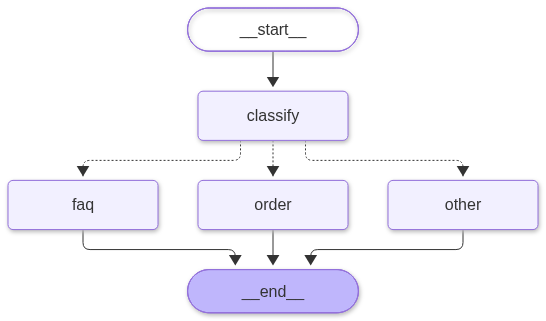

In [27]:

from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))


In [28]:

test_messages = [
    "I want to order chicken pickle",
    "What is the price of chicken pickle?",
    "Hello!"
]

for message in test_messages:
    print("\nCustomer:", message)
    print("Workflow output:")

    for chunk in graph.stream(
        {
            "message": message,
            "intent": "",
            "reply": ""
        },
        stream_mode="updates"
    ):
        print(chunk)



Customer: I want to order chicken pickle
Workflow output:
{'classify': {'intent': 'order'}}
{'order': {'reply': 'Sure! To place your order for chicken pickle, I’ll need:\n\n1. Your name  \n2. Quantity (how many jars)  \n3. Duration (how long you’d like the order to be held)\n\nOnce I have those, I’ll confirm the price and log your order.'}}

Customer: What is the price of chicken pickle?
Workflow output:
{'classify': {'intent': 'faq'}}
{'faq': {'reply': 'Chicken pickle costs\u202fRs\u202f1000 per kilogram.'}}

Customer: Hello!
Workflow output:
{'classify': {'intent': 'other'}}
{'other': {'reply': "Hello! Welcome to Santhi's Pickles. I can help with prices, policies and orders."}}


For all these owner approval is needed...


Customer asks for a discount

Customer requests a refund

Customer wants to cancel an order

Customer requests an unusual delivery arrangement

Customer asks about a policy not in our business facts

Customer requests a custom or special order